# Block 4: Market Stress and Drawdowns

**Objective.** Identify the stress episodes of the S&P 500 over 2015-2026, and measure their depth,
their speed and the time needed to recover.

**Definitions.** The drawdown at date t is the loss from the highest price reached so far:
`DD_t = P_t / max(P_s, s <= t) - 1`. An episode runs from a peak to the date the index recovers that peak.

**Classification rule, fixed before looking at the results.** Standard market conventions are used:
a **correction** is a drawdown of at least 10%, and a **bear market** a drawdown of at least 20%.
Fixing the thresholds in advance avoids tuning them to the data. An episode not yet recovered at the
end of the sample would have a right-censored duration (known to last at least until the last date).

`^GSPC` is a price index: with dividends reinvested, recoveries would be somewhat faster.

In [6]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

from volrisk.config import FIGURES
from volrisk.data import load_raw
from volrisk.returns import cagr
from volrisk.drawdowns import drawdown_series, max_drawdown, drawdown_episodes

In [7]:
prices = load_raw("sp500")["Close"]
dd = drawdown_series(prices)

mdd = max_drawdown(prices)
growth = cagr(prices)

print(f"Maximum drawdown:              {mdd:.2%} on {dd.idxmin().date()}")
print(f"CAGR:                          {growth:.2%}")
print(f"Calmar-type ratio (CAGR/|MDD|): {growth / abs(mdd):.2f}")
print(f"Share of days at a new high:   {(dd == 0).mean():.1%}")
print(f"Share of days 10% or more below the peak: {(dd <= -0.10).mean():.1%}")

Raw data for 'sp500' loaded from 'C:\dev\volatility-analysis\data\raw\sp500.csv'.
Maximum drawdown:              -33.92% on 2020-03-23
CAGR:                          11.66%
Calmar-type ratio (CAGR/|MDD|): 0.34
Share of days at a new high:   12.7%
Share of days 10% or more below the peak: 15.3%


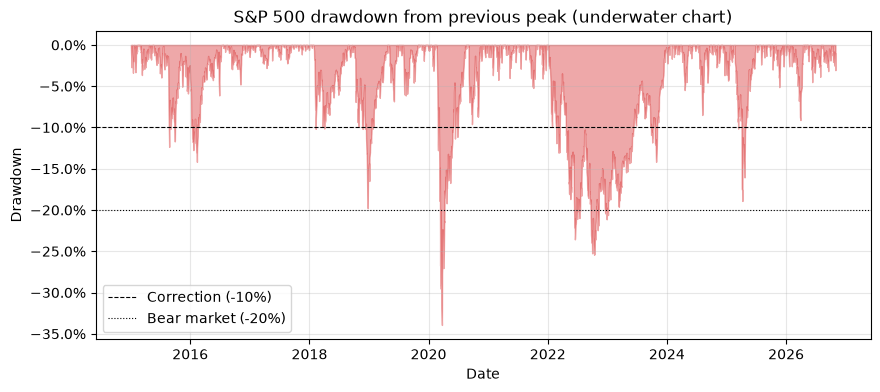

In [8]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.fill_between(dd.index, dd, 0, color="tab:red", alpha=0.4)
ax.axhline(-0.10, color="black", linestyle="--", linewidth=0.8, label="Correction (-10%)")
ax.axhline(-0.20, color="black", linestyle=":", linewidth=0.8, label="Bear market (-20%)")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_title("S&P 500 drawdown from previous peak (underwater chart)")
ax.set_xlabel("Date")
ax.set_ylabel("Drawdown")
ax.legend(loc="lower left")
ax.grid(alpha=0.3)

fig.savefig(FIGURES / "04_underwater.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
episodes = drawdown_episodes(prices, min_depth=0.10)
episodes["type"] = episodes["depth"].apply(lambda d: "Bear market" if d <= -0.20 else "Correction")
episodes.style.format({"depth": "{:.1%}", "days_to_recovery": "{:.0f}"})

,peak,trough,recovery,depth,days_to_trough,days_to_recovery,total_days,recovered,type
0,2020-02-19,2020-03-23,2020-08-18,-33.9%,23,103,126,True,Bear market
1,2022-01-03,2022-10-12,2024-01-19,-25.4%,195,318,513,True,Bear market
2,2018-09-20,2018-12-24,2019-04-23,-19.8%,65,81,146,True,Correction
3,2025-02-19,2025-04-08,2025-06-27,-18.9%,34,55,89,True,Correction
4,2015-05-21,2016-02-11,2016-07-11,-14.2%,183,103,286,True,Correction
5,2018-01-26,2018-02-08,2018-08-24,-10.2%,9,137,146,True,Correction


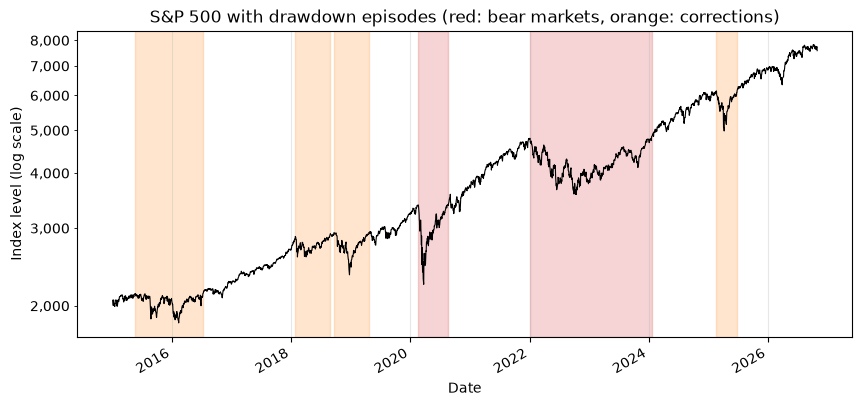

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5))
prices.plot(ax=ax, color="black", linewidth=0.8)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.yaxis.set_minor_formatter(mticker.StrMethodFormatter("{x:,.0f}"))

for _, ep in episodes.iterrows():
    end = ep["recovery"] if ep["recovered"] else prices.index[-1]
    color = "tab:red" if ep["type"] == "Bear market" else "tab:orange"
    ax.axvspan(pd.Timestamp(ep["peak"]), pd.Timestamp(end), color=color, alpha=0.2)

ax.set_title("S&P 500 with drawdown episodes (red: bear markets, orange: corrections)")
ax.set_xlabel("Date")
ax.set_ylabel("Index level (log scale)")
ax.grid(alpha=0.3)

fig.savefig(FIGURES / "04_episodes_on_price.png", dpi=150, bbox_inches="tight")
plt.show()

### Reading the drawdown episodes

Over the full sample, the maximum drawdown is -33.9% (23 March 2020), for a Calmar-type ratio
(CAGR / |maximum drawdown|) of 0.34: the average annual return is about one third of the worst loss.
Even in a market that roughly quadrupled, the index traded at a new high on only 12.7% of trading days,
and stood 10% or more below its previous peak on 15.3% of them.

Six episodes of 10% or more occurred over the sample: two bear markets and four corrections.
All of them were recovered by October 2026, so no duration is censored.

- **COVID-19 (2020), -33.9%: a crash and a fast recovery.** The index fell 34% in only 23 trading days
  and recovered its peak within about five months (126 trading days in total), supported by an
  exceptional monetary and fiscal policy response.
- **2022, -25.4%: a slow decline and a long recovery.** The fall was spread over 195 trading days, and
  regaining the previous peak took more than two years (513 trading days), as interest rates rose
  to fight inflation.
- **Late 2018, -19.8%,** stopped just short of the 20% bear-market threshold on a closing basis. With a
  threshold chosen after looking at the data, it could have been classified differently: this is why
  the rule was fixed in advance.

Depth alone does not describe a crisis: the 2022 episode was shallower than 2020 but kept investors
underwater four times longer. This mirrors Block 2, where 2020 appeared as a short volatility spike
and 2022 as a long period of elevated volatility.

## Block 4: key takeaways

- The maximum drawdown of the S&P 500 over 2015-2026 is **-33.9%** (COVID-19, March 2020).
- Using rules fixed in advance, the sample contains **two bear markets (2020, 2022) and four corrections**.
- **Speed and duration matter as much as depth:** the deepest crisis (2020) was also the fastest to recover,
  while 2022 kept the index below its peak for more than two years.
- Drawdowns describe the losses an investor actually experiences, path by path. **Block 5** turns to
  the daily loss distribution with Value-at-Risk and Expected Shortfall.